In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.model_selection import cross_val_score

# Load your dataset directly
df = pd.read_csv("music_mood_dataset.csv")

# Quick verification
print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
display(df.head())

print("\nMood Distribution:")
print(df['Mood'].value_counts())

Dataset Shape: (586672, 10)

First 5 Rows:


,name,artists,danceability,energy,loudness,acousticness,instrumentalness,valence,tempo,Mood
0,Carve,['Uli'],0.645,0.4450,-13.338,0.674,0.7440,0.127,104.851,Calm
1,Capítulo 2.16 - Banquero Anarquista,['Fernando Pessoa'],0.695,0.2630,-22.136,0.797,0.0000,0.655,102.009,Happy
2,Vivo para Quererte - Remasterizado,['Ignacio Corsini'],0.434,0.1770,-21.180,0.994,0.0218,0.457,130.418,Sad
3,El Prisionero - Remasterizado,['Ignacio Corsini'],0.321,0.0946,-27.961,0.995,0.9180,0.397,169.980,Calm
4,Lady of the Evening,['Dick Haymes'],0.402,0.1580,-16.900,0.989,0.1300,0.196,103.220,Sad



Mood Distribution:
Mood
Sad          212113
Energetic    180274
Happy        152960
Calm          41325
Name: count, dtype: int64


In [2]:
# Data Imputation (Handling Missing Values)
import pandas as pd

# Load dataset
df = pd.read_csv("music_mood_dataset.csv")

# 1. Check missing values before imputation
print("Missing values before imputation:")
print(df.isnull().sum())

# 2. Impute missing text values in 'name' column with a placeholder
df['name'] = df['name'].fillna('Unknown Track')

# (Optional) If any numerical columns ever have missing values, impute using mean/median:
# df['tempo'] = df['tempo'].fillna(df['tempo'].median())

# 3. Verify missing values after imputation
print("\nMissing values after imputation:")
print(df.isnull().sum())

Missing values before imputation:
name                71
artists              0
danceability         0
energy               0
loudness             0
acousticness         0
instrumentalness     0
valence              0
tempo                0
Mood                 0
dtype: int64

Missing values after imputation:
name                0
artists             0
danceability        0
energy              0
loudness            0
acousticness        0
instrumentalness    0
valence             0
tempo               0
Mood                0
dtype: int64


In [3]:
# Merge Mood Categories (Combine Calm & Happy)
# Calm is the smallest/most imbalanced class, so we merge it with Happy
# into a single "Calm_Happy" category. Final classes: Calm_Happy, Energetic, Sad

print("Mood distribution before merging:")
print(df['Mood'].value_counts())

MOOD_MAP = {
    'Calm': 'Calm_Happy',
    'Happy': 'Calm_Happy',
    'Sad': 'Sad',
    'Energetic': 'Energetic'
}

df['Mood'] = df['Mood'].map(MOOD_MAP)

print("\nMood distribution after merging Calm + Happy:")
print(df['Mood'].value_counts())

Mood distribution before merging:
Mood
Sad          212113
Energetic    180274
Happy        152960
Calm          41325
Name: count, dtype: int64

Mood distribution after merging Calm + Happy:
Mood
Sad           212113
Calm_Happy    194285
Energetic     180274
Name: count, dtype: int64


In [4]:
# Encoding
from sklearn.preprocessing import LabelEncoder

# Initialize LabelEncoder
label_encoder = LabelEncoder()

# Fit and transform the 'Mood' column into numeric IDs (0, 1, 2, 3)
df['Mood_encoded'] = label_encoder.fit_transform(df['Mood'])

# Generate and print the explicit class mapping dictionary
class_mapping = dict(zip(label_encoder.classes_, range(len(label_encoder.classes_))))

print("Class Mapping Dictionary:")
print(class_mapping)

print("\nSample Encoded Values:")
print(df[['Mood', 'Mood_encoded']].head(10))

Class Mapping Dictionary:
{'Calm_Happy': 0, 'Energetic': 1, 'Sad': 2}

Sample Encoded Values:
         Mood  Mood_encoded
0  Calm_Happy             0
1  Calm_Happy             0
2         Sad             2
3  Calm_Happy             0
4         Sad             2
5         Sad             2
6         Sad             2
7         Sad             2
8         Sad             2
9  Calm_Happy             0


In [5]:
# Normalization / Feature Scaling
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Define feature matrix (X) and target array (y)
feature_cols = [
    'danceability', 'energy', 'loudness', 
    'acousticness', 'instrumentalness', 'valence', 'tempo'
]

X = df[feature_cols]
y = df['Mood_encoded']

# 2. Train-Test Split prior to scaling (prevents data leakage)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Fit scaler ONLY on training set, then transform both train & test sets
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert scaled arrays back to DataFrames for easy inspection
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=feature_cols)

print("Scaled Features Sample (Training Set):")
display(X_train_scaled_df.head())

Scaled Features Sample (Training Set):


,danceability,energy,loudness,acousticness,instrumentalness,valence,tempo
0,-2.308964,-1.774221,-2.635563,0.799358,-0.409671,-1.882376,-1.927576
1,0.243100,-0.444579,-0.167752,-0.570764,-0.202561,-0.676414,0.307832
2,-2.351097,-1.690499,-2.371667,1.530281,-0.424088,-1.873061,-1.172861
3,-0.081927,-0.408868,-0.258337,-1.223435,-0.252327,-0.773450,0.974888
4,-0.124060,-0.960406,0.520971,0.830888,-0.425252,0.499661,-0.430952


In [6]:
#Data Processing & Feature Preparation
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

# 1. Handle Missing Values
# Fill missing track names with a placeholder to keep metadata intact
df['name'] = df['name'].fillna('Unknown Track')

# 2. Select Features (X) and Target Label (y)
feature_cols = [
    'danceability', 'energy', 'loudness', 
    'acousticness', 'instrumentalness', 'valence', 'tempo'
]
X = df[feature_cols]
y = df['Mood']

# 3. Encode Categorical Target Labels into Numerical Class IDs
# Classes are now: Calm_Happy, Energetic, Sad (Calm + Happy merged)
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# 4. Train-Test Split (80% Train, 20% Test)
# Stratification ensures equal target distribution between train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

# 5. Feature Scaling (Standardization)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Data processing complete!")
print("Training Set Shape:", X_train_scaled.shape)
print("Testing Set Shape :", X_test_scaled.shape)
print("Classes mapping:", dict(zip(label_encoder.classes_, range(len(label_encoder.classes_)))))

Data processing complete!
Training Set Shape: (469337, 7)
Testing Set Shape : (117335, 7)
Classes mapping: {'Calm_Happy': 0, 'Energetic': 1, 'Sad': 2}


In [7]:
# Task 3 – Digitization (tabular)
# Represent the processed table as an array and inspect its dimensions

import numpy as np
import pandas as pd

# Prefer the processed table from Task 2; fall back to the original df if needed
source_df = df_processed if "df_processed" in globals() else df

# Full table as a NumPy object array (mixed types preserved, if any remain)
table_array = source_df.to_numpy()
print("Source DataFrame shape:", source_df.shape)
print("Full table array type:", type(table_array))
print("Full table array shape (rows, columns):", table_array.shape)
print("Full table array ndim:", table_array.ndim)
print()
print("First 3 rows of the array:")
print(table_array[:3])
print()

# Numeric-only view (common ML input form)
numeric_only = source_df.select_dtypes(include=[np.number])
numeric_array = numeric_only.to_numpy()
print("Numeric columns:", list(numeric_only.columns))
print("Numeric array shape (rows, features):", numeric_array.shape)
print("Numeric array dtype:", numeric_array.dtype)
print()
print("First 5 numeric rows:")
print(numeric_array[:5])

Source DataFrame shape: (586672, 11)
Full table array type: <class 'numpy.ndarray'>
Full table array shape (rows, columns): (586672, 11)
Full table array ndim: 2

First 3 rows of the array:
[['Carve' "['Uli']" 0.645 0.445 -13.338 0.674 0.744 0.127 104.851
  'Calm_Happy' 0]
 ['Capítulo 2.16 - Banquero Anarquista' "['Fernando Pessoa']" 0.695 0.263
  -22.136 0.797 0.0 0.655 102.009 'Calm_Happy' 0]
 ['Vivo para Quererte - Remasterizado' "['Ignacio Corsini']" 0.434 0.177
  -21.18 0.994 0.0218 0.457 130.418 'Sad' 2]]

Numeric columns: ['danceability', 'energy', 'loudness', 'acousticness', 'instrumentalness', 'valence', 'tempo', 'Mood_encoded']
Numeric array shape (rows, features): (586672, 8)
Numeric array dtype: float64

First 5 numeric rows:
[[ 6.45000e-01  4.45000e-01 -1.33380e+01  6.74000e-01  7.44000e-01
   1.27000e-01  1.04851e+02  0.00000e+00]
 [ 6.95000e-01  2.63000e-01 -2.21360e+01  7.97000e-01  0.00000e+00
   6.55000e-01  1.02009e+02  0.00000e+00]
 [ 4.34000e-01  1.77000e-01 -2.118

In [8]:
#Exploratory Data Analysis (EDA)
import numpy as np
import pandas as pd

# 1. Inspect Dataset Shapes & Data Types
print("=== DATASET OVERVIEW ===")
print(f"Total Rows (Tracks): {source_df.shape[0]:,}")
print(f"Total Columns: {source_df.shape[1]}")
print("\nData Types:")
print(source_df.dtypes)

# 2. Check for Missing Values & Duplicates
print("\n=== DATA QUALITY AUDIT ===")
print("Missing Values per Column:")
print(source_df.isnull().sum())
print(f"\nDuplicate Rows Count: {source_df.duplicated().sum()}")

# 3. Summary Statistics for Numeric Audio Features
print("\n=== NUMERICAL FEATURES SUMMARY ===")
numeric_cols = source_df.select_dtypes(include=[np.number]).columns
print(source_df[numeric_cols].describe().T[['mean', 'std', 'min', '50%', 'max']])

# 4. Target Class Frequency & Proportions
print("\n=== TARGET CLASS DISTRIBUTION ===")
class_counts = source_df['Mood'].value_counts()
class_percentages = source_df['Mood'].value_counts(normalize=True) * 100
class_summary = pd.DataFrame({'Count': class_counts, 'Percentage (%)': class_percentages.round(2)})
print(class_summary)

=== DATASET OVERVIEW ===
Total Rows (Tracks): 586,672
Total Columns: 11

Data Types:
name                 object
artists              object
danceability        float64
energy              float64
loudness            float64
acousticness        float64
instrumentalness    float64
valence             float64
tempo               float64
Mood                 object
Mood_encoded          int64
dtype: object

=== DATA QUALITY AUDIT ===
Missing Values per Column:
name                0
artists             0
danceability        0
energy              0
loudness            0
acousticness        0
instrumentalness    0
valence             0
tempo               0
Mood                0
Mood_encoded        0
dtype: int64

Duplicate Rows Count: 17907

=== NUMERICAL FEATURES SUMMARY ===
                        mean        std   min         50%      max
danceability        0.563594   0.166103   0.0    0.577000    0.991
energy              0.542036   0.251923   0.0    0.549000    1.000
loudness         

/var/folders/hn/m8w8hbmn22z5qdcz68l65sw00000gn/T/ipykernel_72668/1567488181.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=source_df, x='Mood', palette='magma')


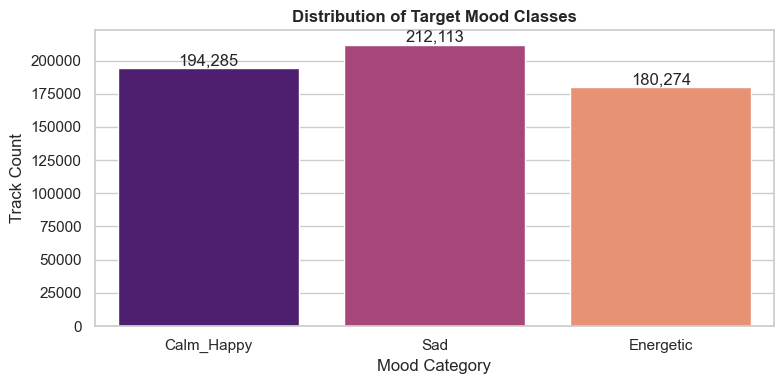

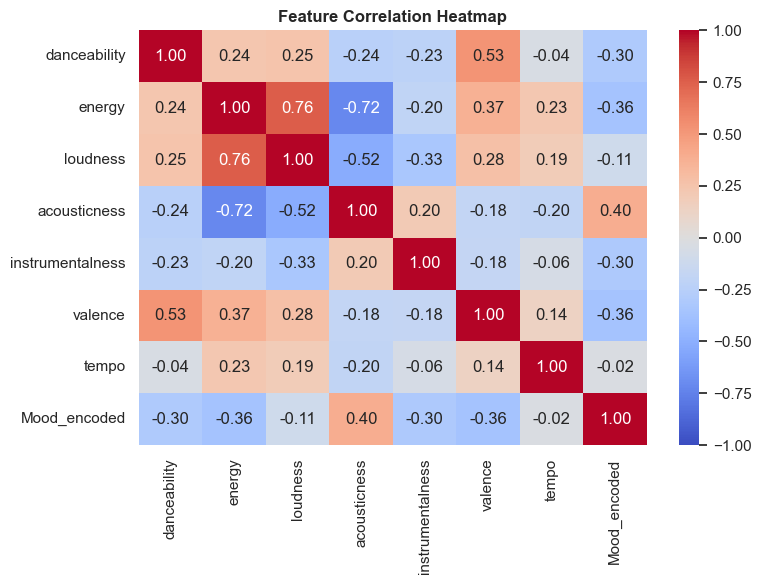

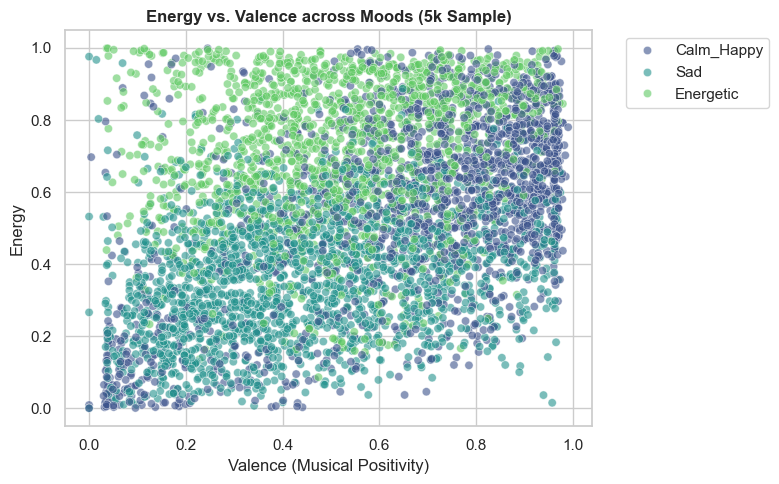

/var/folders/hn/m8w8hbmn22z5qdcz68l65sw00000gn/T/ipykernel_72668/1567488181.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=source_df, x='Mood', y='danceability', palette='Set2')


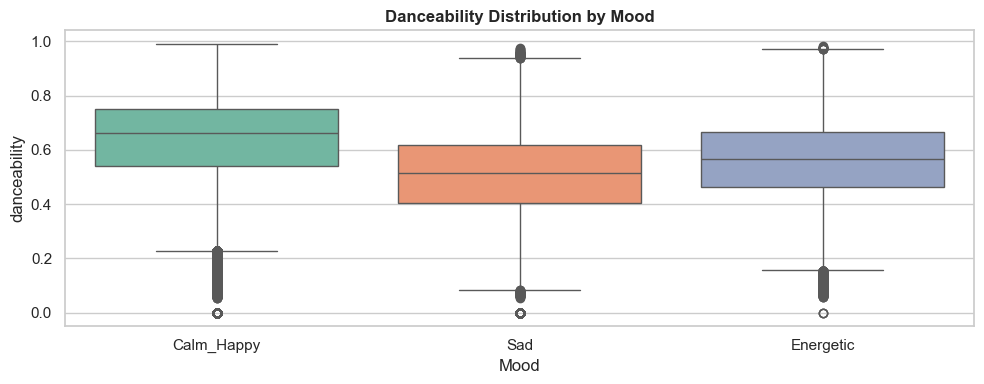

In [9]:
#Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Set overall aesthetic theme
sns.set_theme(style="whitegrid", palette="muted")

# 1. Target Mood Class Balance
plt.figure(figsize=(8, 4))
ax = sns.countplot(data=source_df, x='Mood', palette='magma')
plt.title('Distribution of Target Mood Classes', fontweight='bold', fontsize=12)
plt.xlabel('Mood Category')
plt.ylabel('Track Count')

# Add values above bars
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')
plt.tight_layout()
plt.show()

# 2. Correlation Heatmap of Numeric Features
plt.figure(figsize=(8, 6))
numeric_df = source_df.select_dtypes(include=['number'])
corr_matrix = numeric_df.corr()

sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, cbar=True)
plt.title('Feature Correlation Heatmap', fontweight='bold', fontsize=12)
plt.tight_layout()
plt.show()

# 3. Energy vs. Valence Scatter Plot (Mood Separability)
plt.figure(figsize=(8, 5))
# Sample 5,000 points for clean rendering on large datasets
sample_df = source_df.sample(n=min(5000, len(source_df)), random_state=42)

sns.scatterplot(
    data=sample_df, 
    x='valence', y='energy', hue='Mood', 
    alpha=0.6, palette='viridis'
)
plt.title('Energy vs. Valence across Moods (5k Sample)', fontweight='bold', fontsize=12)
plt.xlabel('Valence (Musical Positivity)')
plt.ylabel('Energy')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# 4. Feature Distribution Plots Across Moods
plt.figure(figsize=(10, 4))
sns.boxplot(data=source_df, x='Mood', y='danceability', palette='Set2')
plt.title('Danceability Distribution by Mood', fontweight='bold', fontsize=12)
plt.tight_layout()
plt.show()

In [10]:
# Task 1 - Primary Random Forest Training
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# 1. Initialize and fit Random Forest classifier
rf_model = RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1)
rf_model.fit(X_train_scaled, y_train)

# 2. Predict on Training and Validation sets
y_train_pred = rf_model.predict(X_train_scaled)
y_val_pred = rf_model.predict(X_test_scaled)

# 3. Calculate Accuracies
train_acc = accuracy_score(y_train, y_train_pred)
val_acc = accuracy_score(y_test, y_val_pred)

print(f"Training Accuracy   : {train_acc * 100:.2f}%")
print(f"Validation Accuracy : {val_acc * 100:.2f}%")

Training Accuracy   : 91.03%
Validation Accuracy : 89.56%


In [11]:
# Task 2 - Random Forest Hyperparameter Tuning
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [8, 12, 16],
    'min_samples_split': [2, 5]
}

grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42, n_jobs=-1),
    param_grid=param_grid,
    cv=3,
    scoring='accuracy',
    n_jobs=-1
)

grid_search.fit(X_train_scaled, y_train)
print(f"Best Parameters : {grid_search.best_params_}")
print(f"Best CV Accuracy: {grid_search.best_score_ * 100:.2f}%")

Best Parameters : {'max_depth': 16, 'min_samples_split': 2, 'n_estimators': 150}
Best CV Accuracy: 90.21%


5-FOLD STRATIFIED CROSS-VALIDATION RESULTS
Fold 1: 89.47%
Fold 2: 89.33%
Fold 3: 89.50%
Fold 4: 89.41%
Fold 5: 89.44%

Mean CV Accuracy : 89.43%
Std Deviation    : 0.06%
Stability        : HIGH (low variance across folds)


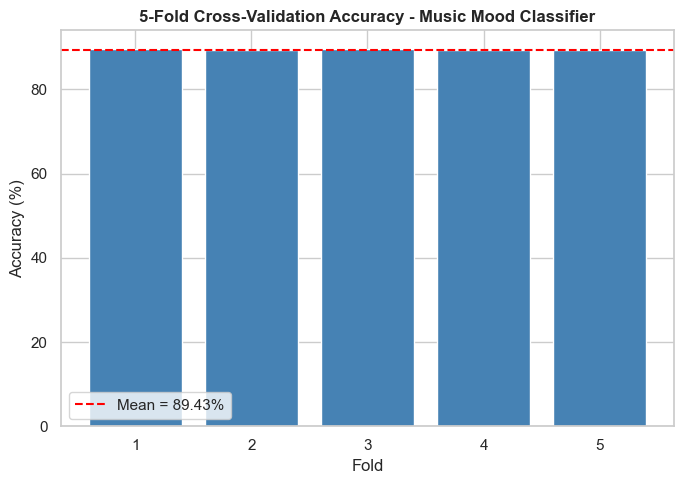

In [12]:
# Task 3 - K-Fold Cross-Validation & Model Stability
from sklearn.model_selection import StratifiedKFold, cross_val_score

# 1. Stratified K-Fold preserves class proportions (Calm_Happy / Energetic / Sad)
#    in every fold, which matters since the merged classes are still not perfectly balanced
K = 5
skf = StratifiedKFold(n_splits=K, shuffle=True, random_state=42)

cv_scores = cross_val_score(
    rf_model, X_train_scaled, y_train,
    cv=skf, scoring='accuracy', n_jobs=-1
)

# 2. Report per-fold scores, mean, and standard deviation
print("=" * 50)
print(f"{K}-FOLD STRATIFIED CROSS-VALIDATION RESULTS")
print("=" * 50)

for i, score in enumerate(cv_scores, start=1):
    print(f"Fold {i}: {score * 100:.2f}%")

print(f"\nMean CV Accuracy : {cv_scores.mean() * 100:.2f}%")
print(f"Std Deviation    : {cv_scores.std() * 100:.2f}%")

# 3. Stability verdict - lower std = more consistent performance across folds
if cv_scores.std() < 0.03:
    stability = "HIGH (low variance across folds)"
elif cv_scores.std() < 0.07:
    stability = "MODERATE"
else:
    stability = "LOW (model is sensitive to data split)"

print(f"Stability        : {stability}")

# 4. Plot fold-by-fold accuracy against the mean
plt.figure(figsize=(7, 5))
plt.bar(range(1, K + 1), cv_scores * 100, color='steelblue')
plt.axhline(cv_scores.mean() * 100, color='red', linestyle='--',
            label=f'Mean = {cv_scores.mean() * 100:.2f}%')
plt.xlabel('Fold')
plt.ylabel('Accuracy (%)')
plt.title(f'{K}-Fold Cross-Validation Accuracy - Music Mood Classifier', fontweight='bold')
plt.xticks(range(1, K + 1))
plt.legend()
plt.tight_layout()
plt.show()

/var/folders/hn/m8w8hbmn22z5qdcz68l65sw00000gn/T/ipykernel_72668/2834302650.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=importance_df, x='Importance', y='Feature', palette='Blues_r')


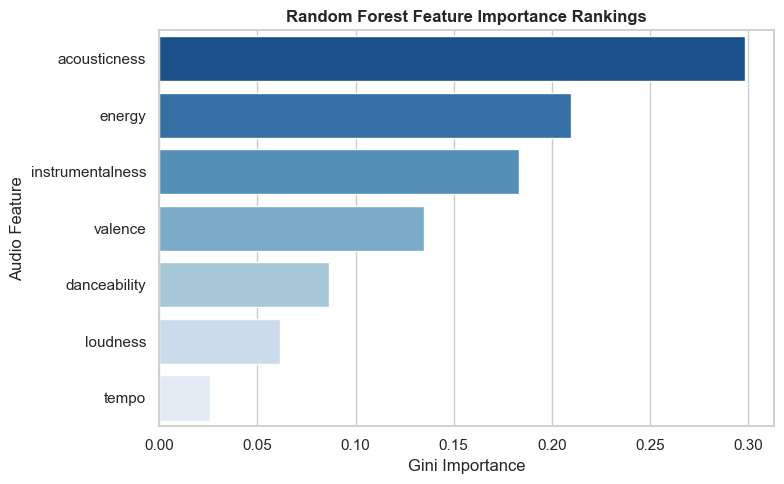

In [13]:
# Task 4 - Random Forest Feature Importance Analysis
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

importance_df = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': rf_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(data=importance_df, x='Importance', y='Feature', palette='Blues_r')
plt.title('Random Forest Feature Importance Rankings', fontweight='bold')
plt.xlabel('Gini Importance')
plt.ylabel('Audio Feature')
plt.tight_layout()
plt.show()

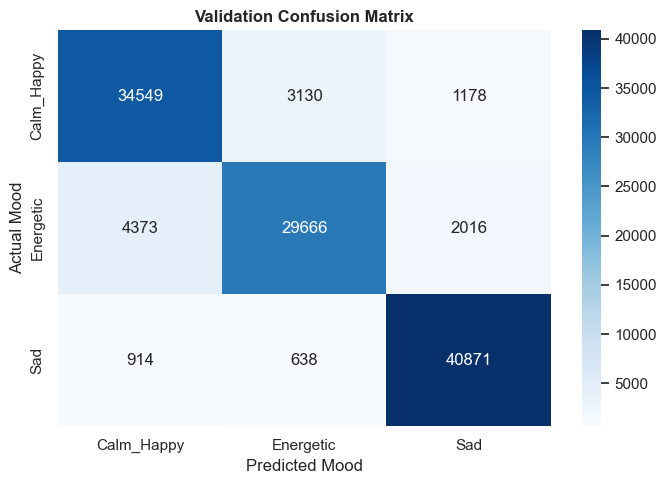


Classification Report:
              precision    recall  f1-score   support

  Calm_Happy       0.87      0.89      0.88     38857
   Energetic       0.89      0.82      0.85     36055
         Sad       0.93      0.96      0.95     42423

    accuracy                           0.90    117335
   macro avg       0.89      0.89      0.89    117335
weighted avg       0.90      0.90      0.89    117335



In [14]:
#Visualization & Final Metrics
# 1. Confusion Matrix
cm = confusion_matrix(y_test, y_val_pred)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title('Validation Confusion Matrix', fontweight='bold')
plt.xlabel('Predicted Mood')
plt.ylabel('Actual Mood')
plt.tight_layout()
plt.show()

# 2. Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_val_pred, target_names=label_encoder.classes_))

In [15]:
import pandas as pd
import numpy as np
from IPython.display import display, HTML

# 1. Define Positive Class
target_positive = 'Calm_Happy'

# 2. Get Predicted Labels & Probabilities
y_val_probs = rf_model.predict_proba(X_test_scaled)  # Probability for each class
confidence_scores = np.max(y_val_probs, axis=1) * 100  # Highest predicted probability percentage

predicted_labels = label_encoder.inverse_transform(y_val_pred) if 'label_encoder' in globals() else y_val_pred

# 3. Align index to extract track names
sample_indices = X_test.index if hasattr(X_test, 'index') else range(len(predicted_labels))
song_names = source_df.loc[sample_indices, 'name'].values if 'source_df' in globals() else df.loc[sample_indices, 'name'].values

# 4. Construct Table DataFrame
sample_df = pd.DataFrame({
    'Song Name': song_names,
    'Ground Truth (Actual)': label_encoder.inverse_transform(y_test) if 'label_encoder' in globals() else y_test,
    'Predicted Label': predicted_labels,
    'Confidence (%)': [f"{score:.2f}%" for score in confidence_scores]
})

# 5. Determine TP, TN, FP, FN
def get_result_type(row):
    actual = row['Ground Truth (Actual)']
    pred = row['Predicted Label']
    
    if actual == target_positive and pred == target_positive:
        return 'TP'
    elif actual != target_positive and pred != target_positive:
        return 'TN'
    elif actual != target_positive and pred == target_positive:
        return 'FP'
    elif actual == target_positive and pred != target_positive:
        return 'FN'

sample_df['Result'] = sample_df.apply(get_result_type, axis=1)

# 6. Display as Left-Aligned HTML Table (n=20)
style_css = """
<style>
    .left-aligned-table table { text-align: left !important; width: 100%; border-collapse: collapse; }
    .left-aligned-table th { text-align: left !important; padding: 8px; background-color: #f2f2f2; }
    .left-aligned-table td { text-align: left !important; padding: 8px; border-bottom: 1px solid #ddd; }
</style>
"""

html_table = sample_df.head(20).to_html(index=False)
display(HTML(f"{style_css}<h3>Sample Predictions (n=20) | Positive Class = '{target_positive}'</h3><div class='left-aligned-table'>{html_table}</div>"))

Song Name,Ground Truth (Actual),Predicted Label,Confidence (%),Result
All Cats Are Grey,Calm_Happy,Calm_Happy,92.00%,TP
Desbaratandome,Sad,Sad,69.78%,TN
Daily Double,Sad,Sad,49.56%,TN
Ay Qué Rico,Calm_Happy,Calm_Happy,93.47%,TP
Chatroulette,Energetic,Energetic,61.41%,TN
À quelle heure on arrive,Energetic,Calm_Happy,72.18%,FP
Leaboy's Lassie (sm) - 2011 Remaster,Calm_Happy,Calm_Happy,67.72%,TP
If I Had a Ribbon Bow,Sad,Sad,98.42%,TN
The Woman is Killin' Me,Sad,Sad,88.57%,TN
Swing,Calm_Happy,Calm_Happy,58.94%,TP
